In [1]:
import os
import glob #os, glob find the dataset files
import gzip
import random #random seeds Python's own random generator
import struct #struct decodes the binary IDX header

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms #transforms supplies the image augmentation and normalization
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Configuration

In [8]:
CFG = {
    "n_total": 1024,      # how many MNIST images to use in total
    "test_frac": 0.2,     # 20% test -> 205 images, 80% train -> 819 images
    "batch_size": 32,
    "epochs": 200,
    "lr": 2e-3,
    "weight_decay": 1e-4,
    "label_smoothing": 0.05,
    "eval_every": 10,
    "seed": 811,
}

random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])
torch.cuda.manual_seed_all(CFG["seed"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


## Load MNIST and split

In [3]:
def read_idx(path): #read_idx decodes the raw MNIST binary format
    with open(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        n_dims = magic & 0xFF
        shape = struct.unpack(">" + "I" * n_dims, f.read(4 * n_dims))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)

def find(pattern):
    hits = [h for h in glob.glob(f"/kaggle/input/**/{pattern}", recursive=True) #** with recursive=True searches every subfolder, so you don't need to know the exact path.
            if os.path.isfile(h)]
    if not hits:
        raise FileNotFoundError(pattern)
    return sorted(hits)[0]

images = np.concatenate([read_idx(find("train-images.idx3-ubyte")),
                         read_idx(find("t10k-images.idx3-ubyte"))])
labels = np.concatenate([read_idx(find("train-labels.idx1-ubyte")),
                         read_idx(find("t10k-labels.idx1-ubyte"))]).astype(np.int64)
print("Full dataset:", images.shape)

idx, _ = train_test_split(np.arange(len(labels)), train_size=CFG["n_total"],
                          stratify=labels, random_state=CFG["seed"])
x_sub, y_sub = images[idx], labels[idx]

x_train, x_test, y_train, y_test = train_test_split(
    x_sub, y_sub, test_size=CFG["test_frac"],
    stratify=y_sub, random_state=CFG["seed"])

print("Train:", x_train.shape, "Test:", x_test.shape)
print("Train per class:", np.bincount(y_train, minlength=10))
print("Test  per class:", np.bincount(y_test, minlength=10))

Full dataset: (70000, 28, 28)
Train: (819, 28, 28) Test: (205, 28, 28)
Train per class: [81 92 81 83 80 74 81 85 80 82]
Test  per class: [20 23 21 21 20 18 20 22 20 20]


## Dataset and Loaders

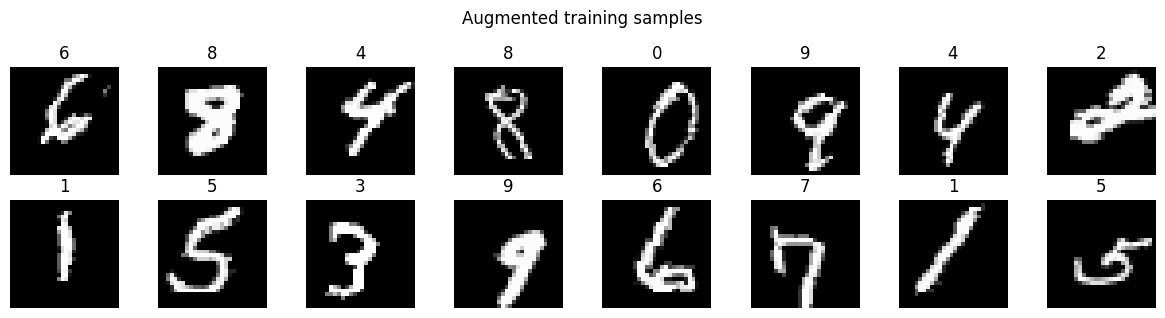

In [4]:
MEAN, STD = 0.1307, 0.3081

class DigitData(Dataset):
    def __init__(self, images, labels, augment):
        self.x = torch.from_numpy(images.copy()).float().div(255.0).unsqueeze(1)
        self.y = torch.from_numpy(labels.copy()).long()
        self.aug = transforms.RandomAffine(degrees=10, translate=(0.1, 0.1),
                                           scale=(0.9, 1.1)) if augment else None
        self.norm = transforms.Normalize((MEAN,), (STD,))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = self.x[i]
        if self.aug is not None:
            img = self.aug(img)
        return self.norm(img), self.y[i]

train_loader = DataLoader(DigitData(x_train, y_train, augment=True),
                          batch_size=CFG["batch_size"], shuffle=True)
test_loader  = DataLoader(DigitData(x_test, y_test, augment=False),
                          batch_size=256, shuffle=False)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, k in zip(axes.flat, range(16)):
    img, lbl = train_loader.dataset[k]
    ax.imshow(img.squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(int(lbl)); ax.axis("off")
plt.suptitle("Augmented training samples"); plt.tight_layout(); plt.show()

## LeNet-5

In [5]:
class LeNet5Mod(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=5, padding=2)
        self.bn1   = nn.BatchNorm2d(8)
        self.conv2 = nn.Conv2d(8, 24, kernel_size=5)
        self.bn2   = nn.BatchNorm2d(24)
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2)
        self.act   = nn.ReLU()
        self.drop  = nn.Dropout(0.25) #5% of the values are randomly switched off
        self.fc1   = nn.Linear(24 * 5 * 5, 128)
        self.fc2   = nn.Linear(128, 64)
        self.fc3   = nn.Linear(64, n_classes)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.pool(self.act(self.bn1(self.conv1(x))))   # N x 8 x 14 x 14
        x = self.pool(self.act(self.bn2(self.conv2(x))))   # N x 24 x 5 x 5
        x = torch.flatten(x, 1)                            # N x 600
        x = self.drop(x)
        x = self.act(self.fc1(x))                          # N x 128
        x = self.drop(x)
        x = self.act(self.fc2(x))                          # N x 64
        return self.fc3(x)                                 # N x 10 logits

model = LeNet5Mod().to(DEVICE)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

LeNet5Mod(
  (conv1): Conv2d(1, 8, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (bn1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(8, 24, kernel_size=(5, 5), stride=(1, 1))
  (bn2): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (act): ReLU()
  (drop): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=600, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)
Parameters: 90930


In [6]:
def fmt(shape):
    return " × ".join(str(v) for v in shape)

def first(v):
    return v[0] if isinstance(v, tuple) else v

def arch_table(model):
    steps = [
        ("conv1",   model.conv1), ("bn1",     model.bn1),
        ("relu",    model.act),   ("pool1",   model.pool),
        ("conv2",   model.conv2), ("bn2",     model.bn2),
        ("relu",    model.act),   ("pool2",   model.pool),
        ("flatten", nn.Flatten()),("dropout", model.drop),
        ("fc1",     model.fc1),   ("relu",    model.act),
        ("dropout", model.drop),  ("fc2",     model.fc2),
        ("relu",    model.act),   ("fc3",     model.fc3),
    ]
    rows = [{"Layer": "input", "Type": "Input", "Weight": "-", "Stride": "-",
             "Padding": "-", "Output size": "N × 1 × 28 × 28", "Params": 0}]

    model.eval()
    x = torch.zeros(1, 1, 28, 28, device=DEVICE)
    with torch.no_grad():
        for name, layer in steps:
            x = layer(x)
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                weight = fmt(layer.weight.shape)
            elif isinstance(layer, nn.BatchNorm2d):
                weight = str(layer.num_features)
            elif isinstance(layer, (nn.MaxPool2d, nn.AvgPool2d)):
                k = layer.kernel_size
                weight = fmt(k if isinstance(k, tuple) else (k, k))
            else:
                weight = "-"
            has_sp = isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.AvgPool2d))
            rows.append({
                "Layer": name,
                "Type": layer.__class__.__name__,
                "Weight": weight,
                "Stride": first(layer.stride) if has_sp else "-",
                "Padding": first(layer.padding) if has_sp else "-",
                "Output size": "N × " + fmt(x.shape[1:]),
                "Params": sum(p.numel() for p in layer.parameters()),
            })
    model.train()
    return pd.DataFrame(rows)

table = arch_table(model)
display(table.style.hide(axis="index"))
print("Total parameters:", table["Params"].sum())

Layer,Type,Weight,Stride,Padding,Output size,Params
input,Input,-,-,-,N × 1 × 28 × 28,0
conv1,Conv2d,8 × 1 × 5 × 5,1,2,N × 8 × 28 × 28,208
bn1,BatchNorm2d,8,-,-,N × 8 × 28 × 28,16
relu,ReLU,-,-,-,N × 8 × 28 × 28,0
pool1,MaxPool2d,2 × 2,2,0,N × 8 × 14 × 14,0
conv2,Conv2d,24 × 8 × 5 × 5,1,0,N × 24 × 10 × 10,4824
bn2,BatchNorm2d,24,-,-,N × 24 × 10 × 10,48
relu,ReLU,-,-,-,N × 24 × 10 × 10,0
pool2,MaxPool2d,2 × 2,2,0,N × 24 × 5 × 5,0
flatten,Flatten,-,-,-,N × 600,0


Total parameters: 90930


# Training

In [9]:
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"],
                              weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])

def run_epoch(loader, train):
    model.train(train)
    loss_sum, correct, seen = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(yb)
            correct  += (logits.argmax(1) == yb).sum().item()
            seen     += len(yb)
    return loss_sum / seen, correct / seen

history = {"epoch": [], "train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, CFG["epochs"] + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    scheduler.step()
    if epoch % CFG["eval_every"] == 0 or epoch == 1:
        te_loss, te_acc = run_epoch(test_loader, train=False)
        for k, v in zip(history, [epoch, tr_loss, tr_acc, te_loss, te_acc]):
            history[k].append(v)
        print(f"epoch {epoch:4d} | train loss {tr_loss:.3f} acc {tr_acc:6.2%} "
              f"| test loss {te_loss:.3f} acc {te_acc:6.2%}")

epoch    1 | train loss 0.461 acc 94.87% | test loss 0.426 acc 96.10%
epoch   10 | train loss 0.463 acc 94.87% | test loss 0.400 acc 96.59%
epoch   20 | train loss 0.427 acc 96.58% | test loss 0.410 acc 96.59%
epoch   30 | train loss 0.407 acc 97.07% | test loss 0.380 acc 98.05%
epoch   40 | train loss 0.396 acc 97.31% | test loss 0.376 acc 98.05%
epoch   50 | train loss 0.397 acc 97.68% | test loss 0.386 acc 98.05%
epoch   60 | train loss 0.367 acc 98.17% | test loss 0.381 acc 97.07%
epoch   70 | train loss 0.367 acc 98.29% | test loss 0.381 acc 98.05%
epoch   80 | train loss 0.354 acc 98.41% | test loss 0.381 acc 97.56%
epoch   90 | train loss 0.371 acc 97.92% | test loss 0.386 acc 98.05%
epoch  100 | train loss 0.355 acc 98.41% | test loss 0.391 acc 97.56%
epoch  110 | train loss 0.347 acc 98.90% | test loss 0.371 acc 98.05%
epoch  120 | train loss 0.347 acc 98.53% | test loss 0.373 acc 98.05%
epoch  130 | train loss 0.333 acc 99.15% | test loss 0.372 acc 98.05%
epoch  140 | train l

## Results

Final test accuracy: 98.05%  (205 test images)


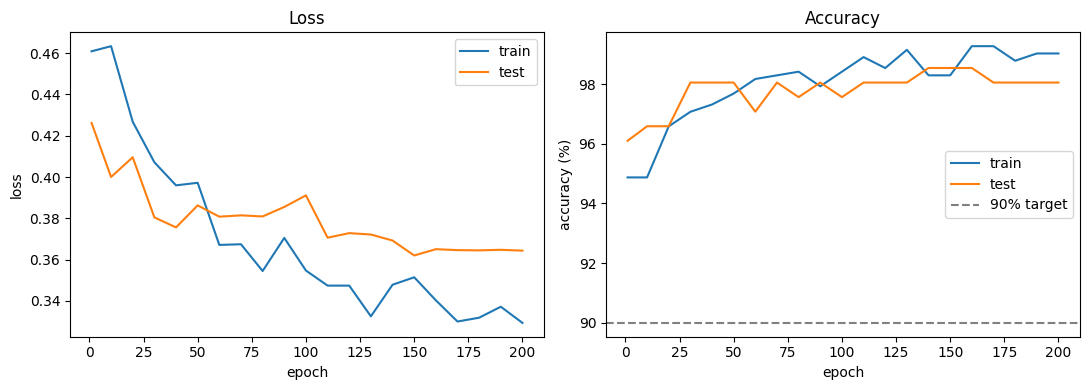

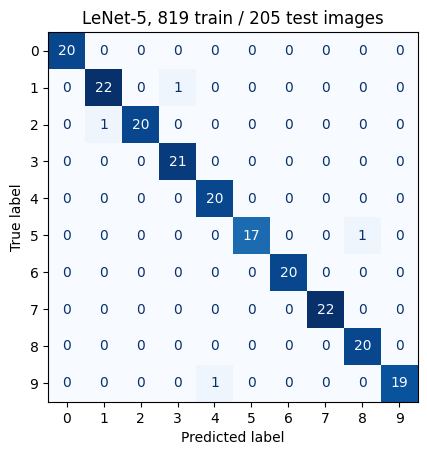

In [10]:
_, final_acc = run_epoch(test_loader, train=False)
print(f"Final test accuracy: {final_acc:.2%}  ({len(y_test)} test images)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(history["epoch"], history["train_loss"], label="train")
a1.plot(history["epoch"], history["test_loss"], label="test")
a1.set_xlabel("epoch"); a1.set_ylabel("loss"); a1.legend(); a1.set_title("Loss")
a2.plot(history["epoch"], [a*100 for a in history["train_acc"]], label="train")
a2.plot(history["epoch"], [a*100 for a in history["test_acc"]], label="test")
a2.axhline(90, ls="--", c="gray", label="90% target")
a2.set_xlabel("epoch"); a2.set_ylabel("accuracy (%)"); a2.legend(); a2.set_title("Accuracy")
plt.tight_layout(); plt.savefig("curves.png", dpi=150); plt.show()

preds, trues = [], []
model.eval()
with torch.no_grad():
    for xb, yb in test_loader:
        preds.append(model(xb.to(DEVICE)).argmax(1).cpu())
        trues.append(yb)
cm = confusion_matrix(torch.cat(trues), torch.cat(preds))
ConfusionMatrixDisplay(cm, display_labels=list(range(10))).plot(cmap="Blues", colorbar=False)
plt.title(f"LeNet-5, {len(y_train)} train / {len(y_test)} test images")
plt.savefig("confusion_matrix.png", dpi=150); plt.show()